# 04 · Evaluation, Explainability & Error Analysis (Phase 4)
**Deliverable:** model comparison report - final held-out test results, influential features, error analysis, threshold trade-offs, and the final deployment model.

### Protocol reminders
* The **test set (128 messages)** is used **exactly once**, here, for the three already-tuned models and their already-chosen thresholds from notebook 03. Nothing is re-tuned after seeing these numbers. (If a result looks disappointing, we report it - we do not go back and change the model.)
* Test-set threshold curves in section 3 are *descriptive only*; the deployed threshold stays the one chosen on validation data.
* 128 messages is small: every metric comes with a bootstrap 95% interval, and I avoid over-reading differences.

In [1]:
import sys; sys.path.insert(0, '..')   # makes src/ importable when the notebook runs from notebooks/
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, json, joblib, warnings, re
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay
from src.preprocessing import *
from src.train import build_pipeline, scam_score
from src.evaluation import *
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid'); pd.set_option('display.max_columns',None,'display.width',250,'display.max_colwidth',130)
d = pd.read_csv('../data/split.csv'); tr = d[d.split=='train'].reset_index(drop=True); te = d[d.split=='test'].reset_index(drop=True)
dev = joblib.load('../models/dev_models.joblib'); sel = json.load(open('../models/selection.json'))
NAMES = {m:dev[m]['config']['name'] for m in dev}; SEL = sel['selected_model']
Xte, yte = te.message_content.values, te.y.values
print('test messages:', len(te), '| scam share:', round(yte.mean(),3), '| selected model (from notebook 03):', NAMES[SEL])
print({m:dev[m]['config']['threshold'] for m in dev})

test messages: 128 | scam share: 0.586 | selected model (from notebook 03): Logistic Regression
{'nb': 0.3147364247731963, 'lr': 0.3203301862375496, 'svm': -0.2217970642456849}

## 1. Single, final test-set evaluation
Two operating points per model:
* **default** threshold (0.5 / margin 0) - what the model does "out of the box";
* **selected** threshold (chosen in notebook 03 for >= 95% validation recall).

In [2]:
scores = {m: scam_score(dev[m]['pipeline'], Xte) for m in dev}
rows=[]
for m in dev:
    for rule,t in [('default',dev[m]['config']['default_threshold']),('selected',dev[m]['config']['threshold'])]:
        mm = metrics(yte, scores[m], t); rows.append(dict(model=NAMES[m], threshold_rule=rule, threshold=round(t,3), **{k:round(v,3) for k,v in mm.items()}))
test_res = pd.DataFrame(rows); test_res.to_csv('../reports/test_results.csv', index=False)
test_res[['model','threshold_rule','threshold','accuracy','recall','precision','f1','roc_auc','tp','fp','fn','tn']]

,model,threshold_rule,threshold,accuracy,recall,precision,f1,roc_auc,tp,fp,fn,tn
0,Naive Bayes,default,0.500,0.844,0.920,0.831,0.873,0.907,69,14,6,39
1,Naive Bayes,selected,0.315,0.836,0.960,0.800,0.873,0.907,72,18,3,35
2,Logistic Regression,default,0.500,0.898,0.920,0.908,0.914,0.933,69,7,6,46
3,Logistic Regression,selected,0.320,0.898,0.960,0.878,0.917,0.933,72,10,3,43
4,Linear SVM,default,0.000,0.883,0.907,0.895,0.901,0.936,68,8,7,45
5,Linear SVM,selected,-0.222,0.898,0.960,0.878,0.917,0.936,72,10,3,43


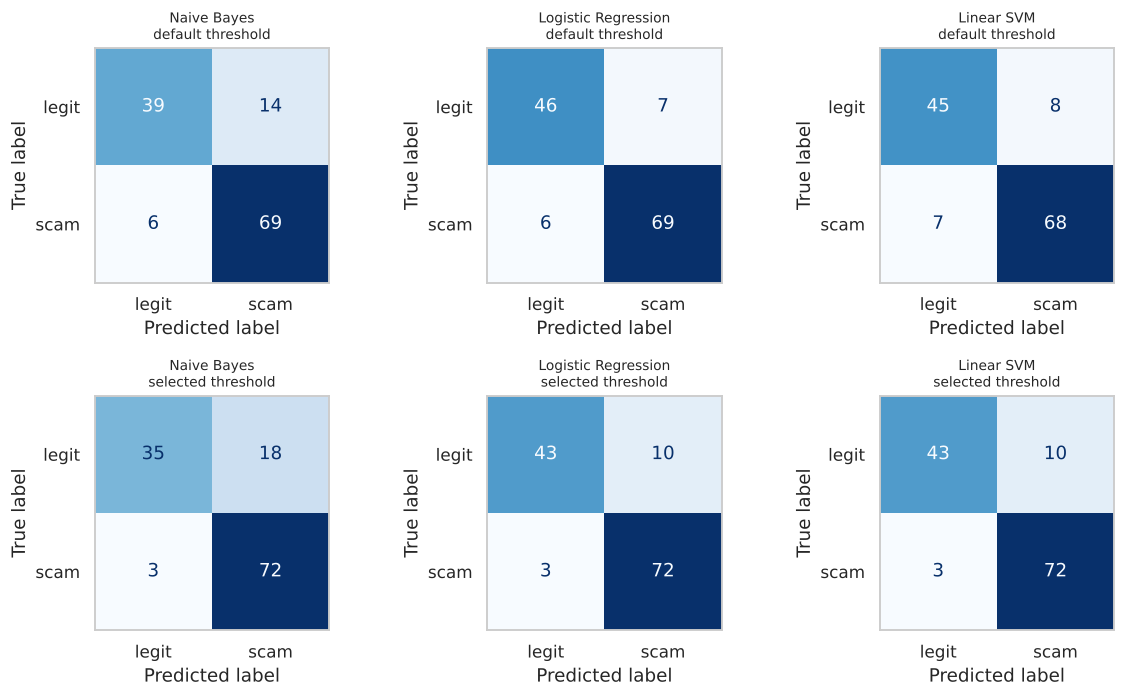

In [3]:
fig,axs=plt.subplots(2,3,figsize=(11,6.5))
for j,m in enumerate(dev):
    for i,rule in enumerate(['default','selected']):
        t = dev[m]['config']['default_threshold' if rule=='default' else 'threshold']
        pred = (scores[m]>=t).astype(int)
        ConfusionMatrixDisplay.from_predictions(yte,pred,display_labels=['legit','scam'],ax=axs[i,j],colorbar=False,cmap='Blues'); axs[i,j].set_title(f'{NAMES[m]}\n{rule} threshold',fontsize=9); axs[i,j].grid(False)
plt.tight_layout(); plt.show()

**How to read a confusion matrix here:** bottom-left = *missed scams* (scam predicted legit, the dangerous error); top-right = *false alarms* (legit flagged as scam). The row "selected" should show fewer missed scams (and more false alarms) than the row "default" - that is the intended trade-off.

## 2. Uncertainty: bootstrap 95% intervals and paired model comparison
With 128 test messages a single number is fragile, so I resample the test messages 2,000 times and report the 2.5-97.5 percentile range. For comparing models I resample the *same* messages for all models (paired), which is more sensitive than comparing unpaired intervals.

In [4]:
rng = np.random.default_rng(RANDOM_STATE); B=2000
idx = rng.integers(0,len(yte),(B,len(yte)))
def boot(m, rule):
    t = dev[m]['config']['default_threshold' if rule=='default' else 'threshold']; out=[]
    for ii in idx:
        if yte[ii].min()==yte[ii].max(): continue
        mm = metrics(yte[ii], scores[m][ii], t); out.append([mm['recall'],mm['precision'],mm['f1'],mm['roc_auc']])
    return np.array(out)
rows=[]; BOOT={}
for m in dev:
    for rule in ['default','selected']:
        a = boot(m,rule); BOOT[(m,rule)] = a
        q = np.percentile(a,[2.5,97.5],axis=0)
        rows.append(dict(model=NAMES[m], rule=rule, **{n:f'{v:.3f} [{lo:.3f}, {hi:.3f}]' for n,v,lo,hi in zip(['recall','precision','F1','ROC-AUC'], np.nanmean(a,0), q[0], q[1])}))
pd.DataFrame(rows)

,model,rule,recall,precision,F1,ROC-AUC
0,Naive Bayes,default,"0.921 [0.855, 0.975]","0.831 [0.747, 0.908]","0.873 [0.813, 0.927]","0.907 [0.847, 0.956]"
1,Naive Bayes,selected,"0.961 [0.914, 1.000]","0.800 [0.719, 0.877]","0.873 [0.814, 0.922]","0.907 [0.847, 0.956]"
2,Logistic Regression,default,"0.920 [0.851, 0.975]","0.907 [0.839, 0.964]","0.913 [0.859, 0.957]","0.932 [0.880, 0.974]"
3,Logistic Regression,selected,"0.960 [0.908, 1.000]","0.877 [0.807, 0.944]","0.916 [0.867, 0.957]","0.932 [0.880, 0.974]"
4,Linear SVM,default,"0.907 [0.835, 0.971]","0.894 [0.822, 0.958]","0.900 [0.844, 0.947]","0.935 [0.885, 0.975]"
5,Linear SVM,selected,"0.960 [0.908, 1.000]","0.877 [0.807, 0.944]","0.916 [0.867, 0.957]","0.935 [0.885, 0.975]"


In [5]:
# paired differences in ROC-AUC and F1 (selected thresholds)
from sklearn.metrics import roc_auc_score
pairs=[('lr','nb'),('svm','nb'),('lr','svm')]; rows=[]
for a,b in pairs:
    da=[];df=[]
    for ii in idx:
        if yte[ii].min()==yte[ii].max(): continue
        ma = metrics(yte[ii],scores[a][ii],dev[a]['config']['threshold']); mb = metrics(yte[ii],scores[b][ii],dev[b]['config']['threshold'])
        da.append(ma['roc_auc']-mb['roc_auc']); df.append(ma['f1']-mb['f1'])
    rows.append(dict(comparison=f'{NAMES[a]} minus {NAMES[b]}', auc_diff=round(np.mean(da),3), auc_95CI=tuple(np.round(np.percentile(da,[2.5,97.5]),3)), f1_diff=round(np.mean(df),3), f1_95CI=tuple(np.round(np.percentile(df,[2.5,97.5]),3))))
pd.DataFrame(rows)

,comparison,auc_diff,auc_95CI,f1_diff,f1_95CI
0,Logistic Regression minus Naive Bayes,0.025,"(-0.005, 0.059)",0.044,"(0.01, 0.082)"
1,Linear SVM minus Naive Bayes,0.028,"(-0.004, 0.063)",0.044,"(0.01, 0.082)"
2,Logistic Regression minus Linear SVM,-0.003,"(-0.013, 0.004)",0.000,"(0.0, 0.0)"


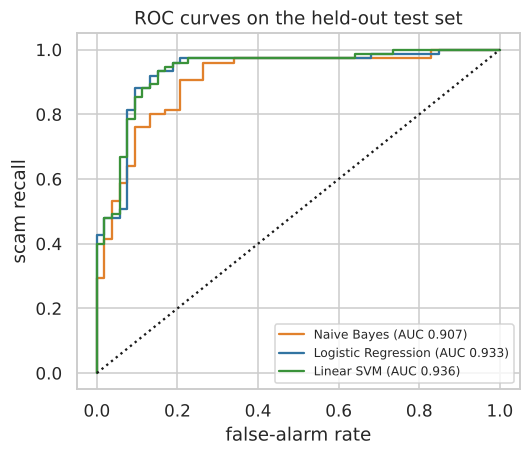

In [6]:
fig,ax=plt.subplots(figsize=(5.2,4.2))
for m,col in zip(dev,['#e1812c','#3274a1','#3a923a']):
    fpr,tpr,_=roc_curve(yte,scores[m]); ax.plot(fpr,tpr,color=col,label=f"{NAMES[m]} (AUC {roc_auc_score(yte,scores[m]):.3f})")
ax.plot([0,1],[0,1],'k:'); ax.set_xlabel('false-alarm rate'); ax.set_ylabel('scam recall'); ax.set_title('ROC curves on the held-out test set'); ax.legend(fontsize=8); plt.show()

**Reading of the actual numbers:**
* Selected-threshold test results: **LR** recall 0.960 / precision 0.877 / F1 0.916 / AUC 0.932; **SVM** identical confusion matrix (72 TP, 10 FP, 3 FN, 43 TN) and AUC 0.935; **NB** recall 0.961 but precision only 0.800 (F1 0.873, AUC 0.907).
* A difference is only trustworthy when its paired 95% interval **excludes 0**. LR - NB in **F1: +0.044 [0.010, 0.082]** excludes 0, so LR really is better than NB at the operating point (mostly through fewer false alarms). In **AUC** the gap (+0.025 [-0.005, 0.059]) is *borderline*: the data cannot firmly separate the ranking quality of the three models. **LR vs SVM: indistinguishable** (AUC diff -0.003 [-0.013, 0.004]; at the chosen thresholds they make exactly the same number of each error type). Consistent with notebook 03.
* Intervals are wide (e.g. LR F1 0.867-0.957) because the test set has only 128 messages. This answers research question 2: *with this much data, the linear models perform alike and above the NB baseline; the choice between LR and SVM should be made on interpretability and probability output (-> LR), not accuracy.*

## 3. Threshold trade-off on the test set (descriptive)
This shows what the dial does on unseen data. **We do not re-select the threshold from this table** - doing so would turn the test set into a tuning set.

In [7]:
m = SEL; ts = np.unique(np.round(np.r_[np.quantile(scores[m],np.linspace(0.05,0.95,12)), dev[m]['config']['threshold'], dev[m]['config']['default_threshold']],3))
tt = threshold_table(yte, scores[m], ts); tt['<- ']=np.where(np.isclose(tt.threshold,round(dev[m]['config']['threshold'],3)),'selected',np.where(np.isclose(tt.threshold,dev[m]['config']['default_threshold']),'default',''))
tt.round(3)

,threshold,recall,precision,f1,missed_scams,false_alarms,<-
0,0.013,1.000,0.620,0.765,0,46,
1,0.036,0.987,0.667,0.796,1,37,
2,0.084,0.973,0.730,0.834,2,27,
3,0.176,0.973,0.811,0.885,2,17,
4,0.320,0.960,0.878,0.917,3,10,selected
5,0.397,0.933,0.875,0.903,5,10,
6,0.500,0.920,0.908,0.914,6,7,default
7,0.607,0.853,0.928,0.889,11,5,
8,0.843,0.733,0.932,0.821,20,4,
9,0.898,0.600,0.918,0.726,30,4,


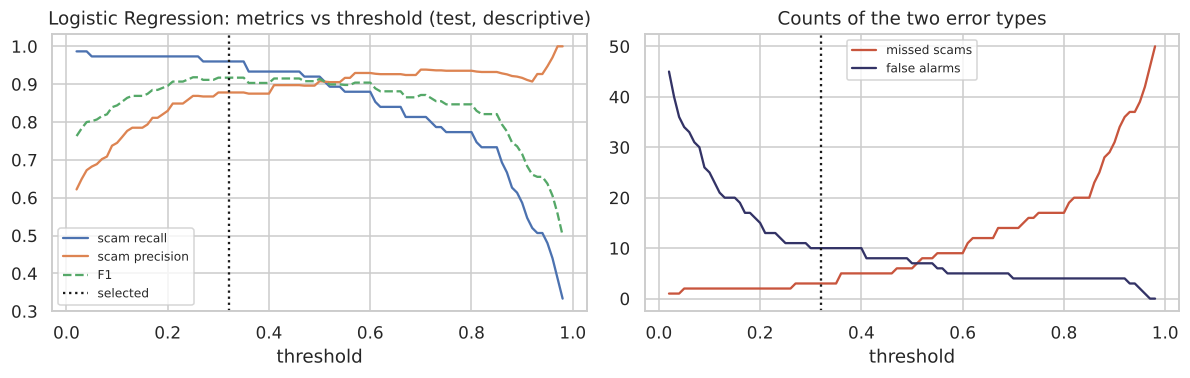

In [8]:
ts = np.linspace(0.02,0.98,97) if SEL!='svm' else np.linspace(-1.2,1.2,97)
tt = threshold_table(yte, scores[SEL], ts)
fig,ax=plt.subplots(1,2,figsize=(11,3.6))
ax[0].plot(tt.threshold,tt.recall,label='scam recall'); ax[0].plot(tt.threshold,tt.precision,label='scam precision'); ax[0].plot(tt.threshold,tt.f1,label='F1',ls='--'); ax[0].axvline(dev[SEL]['config']['threshold'],color='k',ls=':',label='selected'); ax[0].legend(fontsize=8); ax[0].set_xlabel('threshold'); ax[0].set_title(f'{NAMES[SEL]}: metrics vs threshold (test, descriptive)')
ax[1].plot(tt.threshold,tt.missed_scams,color='#c8553d',label='missed scams'); ax[1].plot(tt.threshold,tt.false_alarms,color='#336',label='false alarms'); ax[1].axvline(dev[SEL]['config']['threshold'],color='k',ls=':'); ax[1].legend(fontsize=8); ax[1].set_xlabel('threshold'); ax[1].set_title('Counts of the two error types')
plt.tight_layout(); plt.show()

**Reading:** this is the picture to show a stakeholder. Left of the dotted line (lower thresholds) the system is more cautious: fewer missed scams, more false alarms. The validation-chosen threshold gives a particular balance; if the product owner wanted a gentler tool (fewer false alarms) they could move right, accepting more missed scams - the numbers above quantify the cost.

## 4. Explainability - which words and features drive the predictions? (RQ4)
**Method choice.** The brief says "coefficients and, *optional*, SHAP". For a linear model, each feature's contribution to one message's score is exactly `coefficient x feature value`, which is what SHAP's linear explainer would also give (up to centring on the mean). So coefficients are not a cruder substitute here - they are the exact decomposition, with no extra dependency (SHAP could also not be installed in the build environment). The same decomposition powers the app's per-message explanation.

Number of features: 1254 | handcrafted: 17

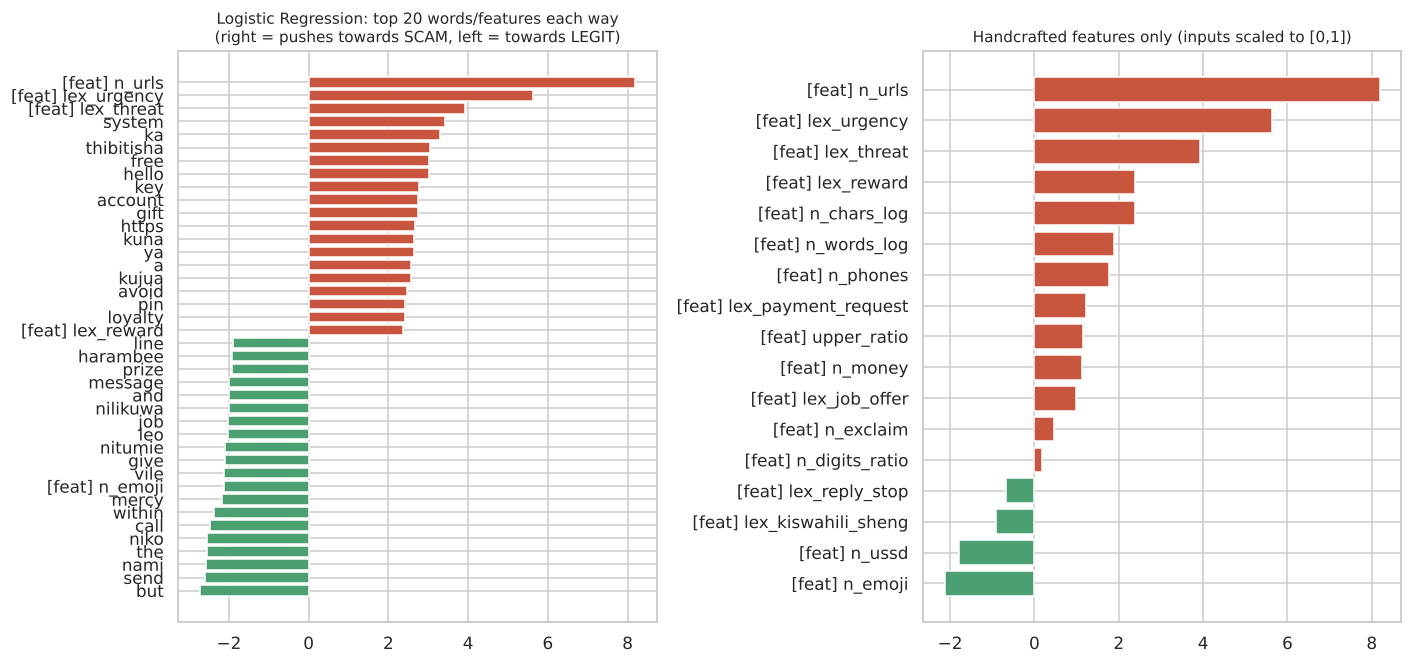

In [9]:
m='lr'; pipe = dev[m]['pipeline']; feats = pipe.named_steps['features']; clf = pipe.named_steps['clf']
names = np.array([n.replace('tfidf__','').replace('hand__','[feat] ') for n in feats.get_feature_names_out()])
coef = pd.Series(clf.coef_.ravel(), index=names).sort_values()
print('Number of features:', len(coef), '| handcrafted:', sum(n.startswith('[feat]') for n in names))
fig,axs=plt.subplots(1,2,figsize=(13,6.2))
top = pd.concat([coef.head(20), coef.tail(20)]); axs[0].barh(top.index, top.values, color=np.where(top.values>0,'#c8553d','#4c9f70')); axs[0].set_title('Logistic Regression: top 20 words/features each way\n(right = pushes towards SCAM, left = towards LEGIT)',fontsize=10)
h = coef[[n for n in coef.index if n.startswith('[feat]')]].sort_values(); axs[1].barh(h.index,h.values,color=np.where(h.values>0,'#c8553d','#4c9f70')); axs[1].set_title('Handcrafted features only (inputs scaled to [0,1])',fontsize=10)
plt.tight_layout(); plt.show()

In [10]:
print('Strongest SCAM-leaning:', list(coef.tail(15)[::-1].index)); print('Strongest LEGIT-leaning:', list(coef.head(15).index))

Strongest SCAM-leaning: ['[feat] n_urls', '[feat] lex_urgency', '[feat] lex_threat', 'system', 'ka', 'thibitisha', 'free', 'hello', 'key', 'account', 'gift', 'https', 'kuna', 'ya', 'a']
Strongest LEGIT-leaning: ['but', 'send', 'nami', 'the', 'niko', 'call', 'within', 'mercy', '[feat] n_emoji', 'vile', 'give', 'nitumie', 'leo', 'job', 'nilikuwa']

**Reading (interpret with the EDA cautions):**
* **Scam-leaning:** the three strongest are the engineered features **link count, urgency wording and threat wording**, followed by `system`, `free`, `account`, `https`, `gift`, `hello`, and the Kiswahili verification word `thibitisha` ("confirm/verify"). So link/urgency/account/reward cues dominate, consistent with notebook 02, and the handcrafted features earned their place.
* **Legit-leaning:** the **informal, personal-conversation vocabulary** (`niko`, `nitumie`, `nilikuwa`, `vile`, `leo`, `nami`, `mercy`), plus emoji count, reply-STOP wording, and function words (`the`, `but`). Note that some words from my *hand-written lexicons* (`send`, `job`, `within`) point to **legit**, the opposite of my intuition - a reminder that a word's meaning depends on context ("send me" in chat vs "send money" in a scam). This is exactly why the brief warned against assuming any word is inherently fraudulent.
* **Kiswahili is not itself a signal:** some Swahili words push to scam (`thibitisha`, `kuna`, `ya`, `ka`), others to legit (`niko`, `leo`). The model is picking up *message style*, not language.
* The very large weights on function words (`the`, `but`, `a`) and `C=16` (weak regularisation) suggest the model partly uses **writing style**, which may not transfer to new scam wording. This is an honest sign of overfitting risk with 515 messages.
* These are **associations learned from this dataset's labels**. In particular, 'legit' words are not guarantees of safety: a scammer could copy them. Likewise, scam-leaning words such as `account` or `kes` also appear in genuine transaction messages, which this dataset contains few of (see the limitation probe in section 6).

### Are the explanations stable? (bootstrap)
A coefficient from 515 messages could flip sign with a slightly different sample. We refit the LR on 100 bootstrap resamples of the *training* set and measure how often each top feature keeps its sign.

In [11]:
rng = np.random.default_rng(1); cfg = dev['lr']['config']; sign = {n:[] for n in coef.index}
for b in range(100):
    ii = rng.integers(0,len(tr),len(tr)); p = build_pipeline('lr',tuple(cfg['ngram']),cfg['hand'],**cfg['params']).fit(tr.message_content.values[ii], tr.y.values[ii])
    nm = [n.replace('tfidf__','').replace('hand__','[feat] ') for n in p.named_steps['features'].get_feature_names_out()]; cc = dict(zip(nm,p.named_steps['clf'].coef_.ravel()))
    for n in sign: sign[n].append(np.sign(cc.get(n,0)))
stab = pd.DataFrame({'coef':coef, 'sign_consistency':{n:max((np.array(v)>0).mean(),(np.array(v)<0).mean()) for n,v in sign.items()}})
topk = pd.concat([stab.sort_values('coef').head(15), stab.sort_values('coef').tail(15)])
print('Share of the 30 strongest features whose sign is the same in >=90% of bootstrap refits:', round((topk.sign_consistency>=0.9).mean(),2))
topk.round(3).sort_values('coef')

Share of the 30 strongest features whose sign is the same in >=90% of bootstrap refits: 0.9

,coef,sign_consistency
but,-2.722,1.00
send,-2.604,1.00
nami,-2.573,0.56
the,-2.559,1.00
niko,-2.556,1.00
call,-2.463,1.00
within,-2.366,0.84
mercy,-2.182,0.99
[feat] n_emoji,-2.127,1.00
vile,-2.123,0.91


**Reading:** 90% of the 30 strongest features keep their sign in at least 90% of refits, so the *headline* explanation is stable. The unstable ones (e.g. `nami` 0.56, `key` 0.76, `within` 0.84) occur in very few messages - treat those as anecdotal. A high `sign_consistency` (near 1) means a reliable explanation.

### Do the three models agree on what matters?

In [12]:
def top_set(m,k=25):
    p=dev[m]['pipeline']; nm=np.array([n.replace('tfidf__','').replace('hand__','[feat] ') for n in p.named_steps['features'].get_feature_names_out()]); c=p.named_steps['clf']
    w = c.coef_.ravel() if hasattr(c,'coef_') else c.feature_log_prob_[1]-c.feature_log_prob_[0]
    o=np.argsort(w); return set(nm[o[-k:]]), set(nm[o[:k]])
sets={m:top_set(m) for m in dev}
rows=[dict(pair=f'{NAMES[a]} vs {NAMES[b]}', scam_top25_overlap=len(sets[a][0]&sets[b][0]), legit_top25_overlap=len(sets[a][1]&sets[b][1])) for a,b in [('lr','svm'),('lr','nb'),('svm','nb')]]
pd.DataFrame(rows)

,pair,scam_top25_overlap,legit_top25_overlap
0,Logistic Regression vs Linear SVM,21,19
1,Logistic Regression vs Naive Bayes,5,4
2,Linear SVM vs Naive Bayes,5,3


**Reading:** a high overlap between LR and SVM (both linear margin models) and a lower one with NB (which weighs rare words very differently - log-probability ratios favour words seen in only one class) is expected. Overlap in the top-25 lists shows which cues are robust to the model family.

### Local explanation for individual messages
Using the same `coefficient x value` decomposition that the app uses (`src.predict.top_terms`), here are three test messages: one correctly caught scam, one correct legit, and one error.

In [13]:
import src.predict as P
bundle = dev['lr']; thr = bundle['config']['threshold']
te['score']=scores['lr']; te['pred']=(te.score>=thr).astype(int)
def show(row,title):
    pos,neg = P.top_terms(bundle,row.message_content,6)
    print(f'=== {title} | true={row.label} | score={row.score:.2f} (threshold {thr:.2f}) -> predicted {"scam" if row.pred else "legit"}')
    print('   ',row.message_content[:200].replace('\n',' '))
    print('    towards SCAM :', [(t,round(v,2)) for t,v in pos[:5]]); print('    towards LEGIT:', [(t,round(v,2)) for t,v in neg[:5]]); print('    warning flags:', warning_indicators(row.message_content)[:4]); print()
show(te[(te.y==1)&(te.pred==1)].sort_values('score',ascending=False).iloc[0],'Correct scam')
show(te[(te.y==0)&(te.pred==0)].sort_values('score').iloc[0],'Correct legit')
err = te[te.y!=te.pred].sort_values('score',ascending=False)
if len(err): show(err.iloc[0],'An error')

=== Correct scam | true=scam | score=1.00 (threshold 0.32) -> predicted scam
    Sunday Flash Sale is On! Get 20% Off using code BREAKFREE20 on non-discounted items except diapers. Order Now until 4 PM. Shop at bit.ly/3BfPu3g. STOP *456*9*5#It's Live! Last Flash Sale of February w
    towards SCAM : [('n_urls', 27.29), ('lex_urgency', 5.63), ('n_chars_log', 2.19), ('n_words_log', 1.69), ('n_exclaim', 0.66)]
    towards LEGIT: [('n_ussd', -6.54), ('up', -0.11), ('with', -0.1), ('every', -0.09), ('800', -0.09)]
    warning flags: ['Contains 10 link(s) - do not click links from unknown senders.', 'Contains a USSD code (*...#) - dialling these can subscribe you to paid services.', 'Urgency wording (e.g. now / today / expires).', 'Mentions paying or sending money / fees.']

=== Correct legit | true=legit | score=0.01 (threshold 0.32) -> predicted legit
    This too Shall Pass🙏🙏 God will see us through the difficult time and our land will be plenty again👐👊🙏🙌"  Reply with 30 for your call rec

## 5. Error analysis (RQ3)
We look at what the selected model gets wrong at its deployed threshold, on the test set. (Also pooled with the out-of-fold training predictions from notebook 03 to get more error examples than 128 messages can provide.)

In [14]:
print(f'Test errors at deployed threshold: {int((te.y!=te.pred).sum())} of {len(te)}  | missed scams: {int(((te.y==1)&(te.pred==0)).sum())} | false alarms: {int(((te.y==0)&(te.pred==1)).sum())}')
oofd = pd.read_csv('../reports/oof_scores_train.csv'); oofd['pred']=(oofd['lr']>=thr).astype(int)
oofd = oofd.merge(tr[['message_content','prelabel','label']], on='message_content', how='left')
FN = oofd[(oofd.y==1)&(oofd.pred==0)]; FP = oofd[(oofd.y==0)&(oofd.pred==1)]
print(f'Pooled out-of-fold training errors: missed scams={len(FN)}, false alarms={len(FP)}')
print('\nMissed scams by risk tier (prelabel):'); print(FN.prelabel.value_counts().to_string())
print('\nTier mix of ALL scams for comparison:'); print(tr[tr.y==1].prelabel.value_counts(normalize=True).round(2).to_string())

Test errors at deployed threshold: 13 of 128  | missed scams: 3 | false alarms: 10
Pooled out-of-fold training errors: missed scams=15, false alarms=34

Missed scams by risk tier (prelabel):
prelabel
1: Moderate-risk scam    9
2: High-risk scam        6

Tier mix of ALL scams for comparison:
prelabel
2: High-risk scam        0.76
1: Moderate-risk scam    0.24

In [15]:
print('--- Missed scams (lowest scores first) ---')
for _,r in FN.sort_values('lr').head(10).iterrows(): print(f'[{r.lr:.2f}] [{r.prelabel[:1]}]', r.message_content[:150].replace('\n',' '))
print('\n--- False alarms (highest scores first) ---')
for _,r in FP.sort_values('lr',ascending=False).head(10).iterrows(): print(f'[{r.lr:.2f}]', r.message_content[:150].replace('\n',' '))

--- Missed scams (lowest scores first) ---
[0.04] [1] Tuma kwa hii 0799848620
[0.07] [2] The key to online privacy is keeping 911538 hidden.
[0.08] [2] God knows you are tired. He knows you are trying. Put him first
[0.12] [2] Hi, It's Phoebe hope you remember. \nEbu nitext WhatsApp kindly. Can't see your no on my end.\nI need to show you the thing you asked about
[0.19] [1] Tunaweza kusaidia kulipa bili zako. Wasiliana nasi kujua vigezo.
[0.22] [2] Hello👋🏻 might you know someone who is looking for a job either part or full time? Needed this week
[0.25] [2] Some of the best days of your life haven't happened yet! Keep going 🙏 Bless your callers with this message today reply with 8 To stop reply with Stop.
[0.25] [1] Confirm your subscription details to avoid disruptions.
[0.25] [1] Uko eligible na surprise gift. Sema uko ready.
[0.26] [1] Kuna nafasi moja ya mwisho. Unaweza kuwa mshindi.

--- False alarms (highest scores first) ---
[1.00] CONGRATULATIONS! From SAFARICOM LIPA NA M-PESA 

In [16]:
def prof(df):
    F = pd.DataFrame([extract_hand_features(t) for t in df.message_content]); return pd.Series({'n':len(df),'median_chars':df.message_content.str.len().median(),'has_link':(F.n_urls>0).mean(),'has_money':(F.n_money>0).mean(),'urgency/reward cue':((F.lex_urgency+F.lex_reward)>0).mean()})
pd.DataFrame({'missed scams':prof(FN),'caught scams':prof(oofd[(oofd.y==1)&(oofd.pred==1)]),'false alarms':prof(FP),'correct legit':prof(oofd[(oofd.y==0)&(oofd.pred==0)])}).round(2)

,missed scams,caught scams,false alarms,correct legit
n,15.00,286.00,34.00,180.00
median_chars,63.00,153.00,139.50,56.50
has_link,0.00,0.47,0.03,0.00
has_money,0.00,0.25,0.09,0.00
urgency/reward cue,0.07,0.64,0.32,0.04


**Reading of the error patterns** (see the printed examples and the profile table):
* **Missed scams** (15 out-of-fold) have **no link and no money amount at all**, are short (median 63 characters vs 153 for caught scams), and 9 of the 15 (60%) are *moderate-risk* although moderate-risk is only 24% of all scams. Examples: a bare phone number ("Tuma kwa hii 07..."), short Kiswahili teasers ("Kuna nafasi moja ya mwisho. Unaweza kuwa mshindi."), "hope you remember me, WhatsApp me", a one-line "job needed this week" pitch, and a devotional-style message with a Skiza-style opt-out. They *look like ordinary conversation* or like the legit promo family, so a bag-of-words model has little to latch onto.
* **False alarms** (34 out-of-fold) are far more revealing: many look like **scams that were labelled `legit`** - e.g. "CONGRATULATIONS! From SAFARICOM LIPA NA M-PESA PROMOTION! You have won Ksh65,000... call 0101922339", a fake "credited to your MPESA ATM" voucher, a "Part time job. Earn 800-5000 KES... Download TG" text, a loan advert, a "sent 4.8M via W/Union to clear the containers" advance-fee story, and the Skiza-template family the annotators labelled inconsistently (notebook 01, section 5a). I cannot verify the true nature of these messages, but it is very plausible that a good part of the false-alarm count reflects **label noise**, not model failure. This means the measured precision (~0.88) is probably an *underestimate* of real precision on these messages, while recall is measured against the same imperfect labels.
* **Implication:** text-only, bag-of-words detection has a ceiling on subtle social-engineering scams. Improvement would need sender information, context (does the user know this contact?), or much more data - listed under future work.

## 6. Limitation probes - behaviour on hand-written examples
These **invented** messages (not from the dataset; clearly illustrative) probe the weaknesses discussed above. They are *not* test results and are not used for any decision.

In [17]:
probes = {
 'Genuine-style M-Pesa receipt': 'UBK1A2B3C4 Confirmed. Ksh500.00 sent to JOHN KAMAU 0712345678 on 12/5/25 at 3:14 PM. New M-PESA balance is Ksh1,250.00. Transaction cost, Ksh7.00.',
 'Friendly Swahili chat': 'Sasa mama, nimefika nyumbani salama. Tutaonana kesho asubuhi.',
 'Obvious prize scam': 'CONGRATULATIONS! You have WON Ksh 250,000 in the Safaricom promo. Claim now at http://bit.ly/claim-ksh-now. Send Ksh 500 registration fee to 0722000000.',
 'Link-free social engineering': 'Hi, sorry I sent you money by mistake, please reverse it to this number when you can, I am stuck.',
 'Account-suspension phishing': 'Dear customer your account has been suspended. Verify your details immediately to avoid permanent closure: www.secure-verify-ke.com',
 'Legit bank alert (no link)': 'Your account ending 4521 was credited with KES 15,000 on 03/05. Thank you for banking with us.',
 'Scam without keywords': 'Hello dear, I have a business proposal that will change your life. Reply to this message so we can talk.'}
rows=[]
for k,t in probes.items():
    s = float(scam_score(bundle['pipeline'],[t])[0]); rows.append(dict(probe=k, scam_score=round(s,2), decision='SCAM' if s>=thr else 'legit', flags='; '.join(f[:38] for f in warning_indicators(t)[:2])))
pd.DataFrame(rows)

,probe,scam_score,decision,flags
0,Genuine-style M-Pesa receipt,0.87,SCAM,Contains a phone number to call/WhatsA; Mentions a money amount.
1,Friendly Swahili chat,0.05,legit,
2,Obvious prize scam,1.00,SCAM,Contains 1 link(s) - do not click link; Contains a phone number to call/WhatsA
3,Link-free social engineering,0.14,legit,
4,Account-suspension phishing,1.00,SCAM,Contains 1 link(s) - do not click link; Urgency wording (e.g. now / today / ex
5,Legit bank alert (no link),0.50,SCAM,Reward / prize / earnings language.; Mentions a money amount.
6,Scam without keywords,0.25,legit,


**Reading (the honest message for the app and the report):** the model flags blatant prize/phishing texts, but (i) a **genuine-looking M-Pesa receipt or bank credit alert can be flagged**, because such messages resemble the fake-confirmation scams in the data and genuine ones are rare in the legit class; and (ii) **link-free social-engineering** texts can pass as legit. These are exactly the failure modes the app must warn about. They also show why conclusions must stay at *"predicts this dataset's labels"*.

## 7. Final deployment model
After the single test evaluation, the selected model (Logistic Regression, its tuned configuration) is **refitted on all 643 messages** (train + test): more data helps a small-data model, and the test set has already served its evaluation purpose. The threshold is carried over from the validation-based choice in notebook 03 (it is *not* re-optimised on the test set). Consequence: the deployed model's own performance can't be measured on unseen data - the honest estimate is the test result above.

In [18]:
cfg = dev[SEL]['config']
final_cfg = dict(model=cfg['model'], ngram=cfg['ngram'], hand=cfg['hand'], params=cfg['params'], threshold=cfg['threshold'], name=cfg['name'])
json.dump(final_cfg, open('../models/final_config.json','w'), indent=1)
from src.train import train_final
path = train_final(); print('saved', path)
res = P.predict('CONGRATULATIONS! You have WON Ksh 250,000. Claim now at http://bit.ly/claim-now')
print({k:(v if k!='scam_terms' and k!='legit_terms' else v[:3]) for k,v in res.items()})
sr = test_res[(test_res.model==NAMES[SEL])&(test_res.threshold_rule=='selected')].iloc[0]
card = dict(title='Explainable ML for SMS Scam Detection (Kenyan mobile-money context)', model=NAMES[SEL], features='TF-IDF word unigrams + 17 handcrafted features', trained_on=int(len(d)),
  held_out_test={k:float(sr[k]) for k in ['accuracy','recall','precision','f1','roc_auc']}, threshold=cfg['threshold'], threshold_rule='highest threshold with >=95% out-of-fold scam recall',
  intended_use='Educational/research prototype: flag possibly suspicious SMS for human review.', not_for='Automatic blocking; legal or financial decisions; non-Kenyan or non-SMS contexts.',
  caveats=['Labels are annotations, not verified truth','643 unique messages','Class mix is not real-world prevalence','Genuine M-Pesa receipts may be flagged','Link-free social-engineering scams may be missed'])
json.dump(card, open('../models/model_card.json','w'), indent=1); card['held_out_test']

saved /home/claude/project/sms-scam-detection/models/final_model.joblib
{'score': 0.9984247473795084, 'threshold': 0.3203301862375496, 'label': 'scam', 'indicators': ['Contains 1 link(s) - do not click links from unknown senders.', 'Urgency wording (e.g. now / today / expires).', 'Reward / prize / earnings language.', 'Mentions a money amount.'], 'scam_terms': [('lex_urgency', 2.4715677337222908), ('lex_reward', 1.818297290014001), ('n_chars_log', 1.438224858522573)], 'legit_terms': [('000', -0.23513684495515397), ('have', -0.14318530087390724), ('at', -0.11740591365889576)]}

{'accuracy': 0.898, 'recall': 0.96, 'precision': 0.878, 'f1': 0.917, 'roc_auc': 0.933}

## 8. Summary of findings by research question
| RQ | Answer (see the evidence above and in notebook 03) |
|---|---|
| 1 Performance | Test (128 msgs, selected threshold): LR recall 0.96, precision 0.88, F1 0.92, ROC-AUC 0.93 (95% CI for F1 0.87-0.96). Intervals are wide and the labels are annotations, not verified truth. |
| 2 Model comparison | LR ~ SVM > Naive Bayes (CV AUC 0.952 / 0.952 / 0.924; test F1 gap LR-NB +0.044, CI excludes 0). LR vs SVM indistinguishable -> LR selected for interpretability and probabilities. |
| 3 Scam vs false-alarm balance | Deployed threshold (0.32) buys >= 95% validation recall: on test 3 missed scams and 10 false alarms of 128 (vs 6 and 7 at the default 0.5). |
| 4 Explainability | Links/account-money/urgency/reward cues push to scam; informal personal-conversation vocabulary (English/Kiswahili/Sheng) and emojis push to legit (Kiswahili itself is not a signal); headline features stable under bootstrap; associations not causes. |
| 5 Generalisation / leakage | Naive evaluation overstated F1 by ~1.3-1.6 points (mostly exact duplicates); results are robust to the near-duplicate threshold; remaining errors are short link-free scams, probable label noise, and look-alike genuine messages. |